# Planta Física: aprendemos algoritmos genéticos con cuatro decisiones

MA2015.201 · Octubre de 2026 · **Grupo:** MA2015.201 · **Equipo 10**


**Integrantes**

A01668399 | Mariana Ponce Suastes

A01661759 | Mia Mac Namara Bustos

A00570712 | Aranza Narcia González


**Rotación de responsabilidades** (anotar solo lo que efectivamente ocurrió):

| Avance | Programación | Revisión | Verificación |
|---|---|---|---|
| Investigación | Mariana | Mia | Aranza |


# Investigación

## 1. Definimos el problema

Asignamos una fracción de agua tratada a cada edificio para reducir el agua potable. Usamos demandas agregadas reales de marzo de 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 y Aulas 2 = 683 m³. Conservamos ese orden. Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

Adoptamos 1,410 m³ como **capacidad didáctica**, tomada de la calibración docente existente; no es una capacidad confirmada por el socio. También tratamos los límites por edificio como supuestos didácticos.

Codificamos $k=(k_1,k_2,k_3,k_4)$ con enteros: $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$. Interpretamos $x_i=k_i/10$. Por ejemplo, el gen 6 representa 60%

### 1.1 Formulación y supuestos

**Decisión**

Decidimos, para cada uno de los cuatro edificios, qué fracción de su demanda mensual se cubre con agua tratada (reúso); el resto se cubre con agua potable. Buscamos **minimizar el agua potable** usada en el mes sin pedirle a la planta más agua tratada de la que puede producir.

**Genes**

El cromosoma es $k=(k_1,k_2,k_3,k_4)$ y conserva siempre este orden: Aulas 1, Biblioteca, Cedetec, Aulas 2. Cada gen es un nivel entero y cada nivel vale diez puntos porcentuales:

- nivel entero $k_i$ (lo que evoluciona el algoritmo),
- fracción $x_i=k_i/10$ (qué parte de la demanda del edificio se trata),
- volumen $T_i=D_i\,x_i$ en m³ (agua tratada del edificio $i$).

Ejemplo: $k_1=6 \Rightarrow x_1=0.60 \Rightarrow$ 60 % de reúso $\Rightarrow T_1=847\times0.6=508.2$ m³.

**Dominios y supuestos didácticos**

Cada gen $k_i$ es un nivel entero que representa diez puntos porcentuales, de modo que el espacio de búsqueda es finito ($9\times9\times7\times9=5103$ combinaciones) y la mutación puede mover un gen un nivel hacia arriba o hacia abajo. El valor 0 equivale a no reutilizar agua en ese edificio, el valor 1 equivale a reutilizar el 10 % y así sucesivamente hasta llegar al reúso máximo.

*Supuestos didácticos:* Se establecen como supuestos didácticos del ejercicio (y no como datos de consumo observado) los límites máximos de reúso por edificio: un máximo de 80 % ($k_i \in \{0,\ldots,8\}$) para Aulas 1, Biblioteca y Aulas 2, y un máximo de 60 % ($k_3 \in \{0,\ldots,6\}$) para Cedetec.

**Datos (consumos observados, marzo de 2025)**

Aquí $D_i$ es la demanda mensual del edificio $i$ y $Q=\sum_{i=1}^4 D_i$ es la demanda total de los cuatro edificios.

| Edificio | Gen | Demanda $D_i$ (m³) | Dominio de $k_i$ |
|---|---|---|---|
| Aulas 1 | $k_1$ | 847.00 | {0,…,8} |
| Biblioteca | $k_2$ | 462.00 | {0,…,8} |
| Cedetec | $k_3$ | 284.21 | {0,…,6} |
| Aulas 2 | $k_4$ | 683.00 | {0,…,8} |
| **Total** | | **$Q=2276.21$** | |

$C=1410$ m³ es la cantidad máxima de agua tratada que el ejercicio supone que la planta puede producir en el mes.

**Procedencia** 

Las demandas son los consumos agregados de marzo de 2025 del archivo `consumo_agua_2023_2026.csv` (cuatro registros, sin banderas de imputación, cero ni anomalía). La capacidad proviene de `parametros_reto.csv`. 

**Fórmulas**

Todo se mide en m³, salvo $F$, que no tiene unidades.

$$T_i=D_i\frac{k_i}{10},\qquad P_i=D_i-T_i,\qquad T=\sum_{i=1}^4 T_i,\qquad P=Q-T,\qquad E=\max(0,\,T-C).$$

- $T_i$: agua **tratada** que recibe el edificio $i$. $T$ es el total tratado, es decir, lo que la planta tendría que producir.
- $P_i$: agua **potable** que le falta al edificio $i$ después del reúso. $P$ es el total de agua potable y es la cantidad que queremos minimizar.
- $E$: **exceso de capacidad**, o cuánta agua tratada se pide por encima de lo que la planta puede producir. Si $T\le C$, entonces $E=0$ y el plan es factible. Si $T>C$, entonces $E>0$ y el plan es infactible.

**Objetivo y aptitud**

Se busca minimizar $P$ sujeto a los dominios y a $T\le C$. Minimizamos el agua potable porque cada metro cúbico que se cubre con agua tratada es un metro cúbico de agua potable que no se consume. Para ordenar candidatos usamos una aptitud $F$ donde **menor es mejor**:

$$F(k)=\begin{cases}P/Q & \text{si } T\le C \text{ (factible)}\\ 1+E/C & \text{si } T>C \text{ (infactible)}\end{cases}$$

- Si el plan es factible, $F=P/Q$ es la fracción de la demanda total cubierta con agua potable. Mientras menos agua potable use, menor es $F$.
- Si el plan es infactible, $F=1+E/C$ penaliza el exceso de capacidad y siempre da $F>1$, así que nunca le gana a un plan factible.

Un plan factible tiene $F\le1$. La capacidad se comprueba con tolerancia numérica de $10^{-8}$ m³.

**Alcance** 

El resultado describe un modelo académico de **un solo mes** (marzo de 2025). No es una recomendación hidráulica ni sanitaria validada.

In [17]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

## 2. Calculamos agua y aptitud

Definimos agua tratada $T=\sum_iD_i k_i/10$, agua potable $P=\sum_iD_i-T$ y exceso $E=\max(0,T-C)$. Minimizamos $P$ sujeto al dominio y $T\le C$.

Ordenamos candidatos con $F=P/\sum D_i$ si son factibles y $F=1+E/C$ si exceden la capacidad. **Menor aptitud es mejor.** Una solución factible tiene $F\le1$; una infactible tiene $F>1$. Usamos tolerancia numérica de $10^{-8}$ m³.

In [18]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

### 2.1 Cálculo manual del candidato $k=(6,6,6,6)$

Todos los genes están en su dominio (el máximo de Cedetec es 6, y $6\le6$). Con $x_i=0.6$ en los cuatro edificios:

| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i=D_ix_i$ (m³) | $P_i=D_i-T_i$ (m³) |
|---|---|---|---|---|---|
| Aulas 1 | 847.00 | 6 | 0.6 | $847\times0.6=508.200$ | $847-508.2=338.800$ |
| Biblioteca | 462.00 | 6 | 0.6 | $462\times0.6=277.200$ | $462-277.2=184.800$ |
| Cedetec | 284.21 | 6 | 0.6 | $284.21\times0.6=170.526$ | $284.21-170.526=113.684$ |
| Aulas 2 | 683.00 | 6 | 0.6 | $683\times0.6=409.800$ | $683-409.8=273.200$ |
| **Total** | **2276.21** | | | **$T=1365.726$** | **$P=910.484$** |

**Comprobaciones y resultado.** $T_i+P_i=D_i$ en cada fila (por ejemplo, $508.2+338.8=847$).

$T=508.2+277.2+170.526+409.8=1365.726$ m³ y $P=338.8+184.8+113.684+273.2=910.484$ m³, de modo que $T+P=1365.726+910.484=2276.210=Q$.

- Exceso: $E=\max(0,\,1365.726-1410)=\max(0,\,-44.274)=0$ m³.
- Factibilidad: $T=1365.726\le1410$ (y $E=0\le10^{-8}$), así que **es factible** y le corresponde la rama $F=P/Q$.
- Aptitud: $F=910.484/2276.21=0.4$ (sin unidades).

#### 2.1.1 Comparación con `evaluate` 

Comparamos las cinco claves: `treated` ($T$), `potable` ($P$), `excess` ($E$), `feasible` (factibilidad) y `fitness` ($F$). Los valores manuales son los de la sección 2.1.

In [19]:
genes = np.array([6, 6, 6, 6], dtype=int)
resultado = evaluate(genes)
resultado

manual = dict(treated=1365.726, potable=910.484, excess=0.0, fitness=0.4)

print(f"{'cantidad':<10}{'manual':>14}{'evaluador':>22}{'diferencia':>14}")
for clave in ("treated", "potable", "excess", "fitness"):
    dif = resultado[clave] - manual[clave]
    print(f"{clave:<10}{manual[clave]:>14.6f}{resultado[clave]:>22.15f}{dif:>14.1e}")
print("Factibilidad manual: True | evaluador:", resultado["feasible"])

cantidad          manual             evaluador    diferencia
treated      1365.726000  1365.725999999999885      -2.3e-13
potable       910.484000   910.484000000000151       1.1e-13
excess          0.000000     0.000000000000000       0.0e+00
fitness         0.400000     0.400000000000000       5.6e-17
Factibilidad manual: True | evaluador: True


**Comparación.** 

Las cuatro cantidades numéricas coinciden con el cálculo manual. Las diferencias son del orden de $10^{-13}$ y vienen solo de la aritmética de punto flotante (los decimales se guardan en binario). Mostramos la columna manual con seis decimales; los cálculos conservan toda la precisión. Las dos decisiones de factibilidad coinciden (factible en ambos casos, porque $E=0$). No hubo que corregir nada: el orden de los edificios, las unidades y la conversión $x_i=k_i/10$ son los mismos en las fórmulas y en el código.


### 2.2 Pruebas con demás candidatos

Así como en la sección anterior con el candidato 60% uniforme, se evaluaran los candidatos extremos, es decir, el candidato de 0 reúso $k=(0,0,0,0)$ y los máximos del dominio $k=(8,8,6,8)$


#### 2.2.1 Candidato $k=(0,0,0,0)$
| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i=D_ix_i$ (m³) | $P_i=D_i-T_i$ (m³) |
|---|---|---|---|---|---|
| Aulas 1 | 847.00 | 0 | 0.0 | $847\times0=0.000$ | $847-0=847.000$ |
| Biblioteca | 462.00 | 0 | 0.0 | $462\times0=0.000$ | $462-0=462.000$ |
| Cedetec | 284.21 | 0 | 0.0 | $284.21\times0=0.000$ | $284.21-0=284.210$ |
| Aulas 2 | 683.00 | 0 | 0.0 | $683\times0=0.000$ | $683-0=683.000$ |
| **Total** | **2276.21** | | | **$T=0$** | **$P=2276.21$** |

$P=2276.21-0=2276.21$ m³ y $E=\max(0,\,0-1410)=0$ m³. Como $T=0\le1410$, es factible y $F=P/Q=2276.21/2276.21=1$.

#### 2.2.2 Candidato $k=(8,8,6,8)$


| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i$ (m³) | $P_i=D_i-T_i$ (m³) |
|---|---|---|---|---|---|
| Aulas 1 | 847.00 | 8 | 0.8 | $847\times0.8=677.600$ | $847-677.600=169.400$ |
| Biblioteca | 462.00 | 8 | 0.8 | $462\times0.8=369.600$ | $462-369.600=92.400$ |
| Cedetec | 284.21 | 6 | 0.6 | $284.21\times0.6=170.526$ | $284.21-170.526=113.684$ |
| Aulas 2 | 683.00 | 8 | 0.8 | $683\times0.8=546.400$ | $683-546.400=136.600$ |
| **Total** | **2276.21** | | | **$T=1764.126$** | **$P=512.084$** |

$P=2276.21-1764.126=512.084$ m³ y $E=1764.126-1410=354.126$ m³. Como $T=1764.126>1410$, le corresponde la rama penalizada: $F=1+E/C=1+354.126/1410\approx1.2512$.

#### 2.2.3 Evaluación de candidatos

In [20]:
cases = [np.zeros(4, dtype=int), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


### 2.3 Interpretación

**Cero reúso $k=(0,0,0,0)$.** 

Es factible. Todos los $k_i$ valen 0, así que $x_i=k_i/10=0$ y no se utiliza agua tratada en ningún edificio ($T=0$). La condición de factibilidad es que el agua tratada no supere la capacidad: $0\le1410$, por lo que no hay exceso ($E=0$). Es el plan sin reúso: toda la demanda se cubre con agua potable ($P=Q$) y $F=1$.

**Cromosoma máximo $k=(8,8,6,8)$.** 

No es factible, aunque **todos sus genes son válidos**: cada $k_i$ está dentro del dominio de su edificio. Los dominios limitan a cada edificio por separado, mientras que la capacidad limita la **suma** de los volúmenes tratados. Al sumar, $T=677.6+369.6+170.526+546.4=1764.126$ m³, que excede la capacidad en $E=354.126$ m³. Como este exceso es mayor que la tolerancia ($10^{-8}$ m³), el plan es infactible.

**Rama de aptitud.** 

Por ser infactible, le corresponde la rama penalizada: $F=1+E/C=1+354.126/1410\approx1.2512>1$. **Físicamente**, $E=354.126$ m³ es el agua tratada que el plan exige y que la planta no puede producir con la capacidad supuesta. Aunque este plan usa menos agua potable ($P=512.084$ m³ frente a $910.484$ m³ de $(6,6,6,6)$), lo descartamos por infactible.

## 3. Generamos una población

Una población es una lista de candidatos. Muestreamos cada gen dentro de su dominio, incluidos los extremos. El muestreo no garantiza capacidad: la función de aptitud ordena también los candidatos infactibles. Fijamos la semilla para reproducir esta demostración.

In [21]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. Seleccionamos padres mediante torneo

Tomamos dos candidatos distintos al azar y elegimos el de menor $F$. Repetimos para elegir otro padre; un mismo individuo puede ganar varios torneos. La selección favorece aptitudes bajas sin ordenar siempre toda la población. Devolvemos una copia para proteger el original.

In [22]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. Combinamos información con cruza de un punto

Elegimos un corte entre posiciones y tomamos el inicio del primer padre y el final del segundo. Conservamos la posición de cada edificio. Con padres $(6,6,6,6)$ y $(8,2,4,3)$ y corte 2 obtenemos $(6,6,4,3)$. La cruza preserva dominios, pero puede producir exceso de capacidad.

In [23]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. Introducimos variación con mutación

Aplicamos la probabilidad a **cada gen**, no al cromosoma completo. Cada gen elegido sube o baja un nivel válido. En cero sólo subimos; en el máximo sólo bajamos. Con $p=0.25$ y cuatro genes, esperamos un gen seleccionado por hijo en promedio, no exactamente uno. La mutación puede mejorar o empeorar la aptitud.

In [24]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. Reemplazamos la población y conservamos una élite

Copiamos el mejor individuo sin modificarlo y llenamos las posiciones restantes con hijos. Mantenemos el tamaño de la población. El elitismo evita perder el mejor valor de aptitud; no demuestra que ya encontramos el óptimo. Con una copia independiente, mutar un hijo no modifica al padre ni a la élite.

In [25]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. Cerramos el ciclo

Inicializamos, evaluamos y repetimos selección, cruza, mutación y reemplazo durante un número fijo de generaciones. Registramos el mejor $F$ inicial y después de cada generación. Con 20 generaciones obtenemos 21 valores, incluido el estado inicial. No esperamos una mejora en cada paso.

In [26]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

# Desarrollo

### Único operador modificado: Selección. 
La cruza (`crossover`), la mutación (`mutate`), el reemplazo generacional y la élite (`next_generation`) son exactamente los de la base; el evaluador (`evaluate`) y la generación de la población inicial (`random_individual`) tampoco cambian. El único cambio de código es el parámetro `size=2` → `size=5` en `rng.choice(...)`, que modifica el comportamiento del operador (cuántos candidatos compiten y, por tanto, qué padres se eligen).

### Limitación que atendemos

Con torneo de 2 sobre 20 individuos la **presión de selección es baja**: el mejor individuo del torneo siempre gana, pero cada torneo sólo compara dos candidatos al azar, así que un individuo mediocre gana siempre que se enfrenta a otro peor y el mejor individuo puede no ser muestreado en ningún torneo de una generación. Como cada generación crea sólo 19 hijos y hay pocas generaciones (20), la búsqueda puede avanzar lentamente hacia asignaciones cercanas a $T=1410$ m³, que son las que dan menor agua potable sin exceder la capacidad.

### Hipótesis

Si el torneo compara **cinco** candidatos distintos (en vez de dos) y gana el de menor $F$, los padres elegidos tendrán en promedio mejor aptitud. Esperamos que la población se concentre más rápido en asignaciones factibles con $T$ cercano a 1410 m³ y que el algoritmo encuentre un candidato factible con **menor agua potable $P$** que el de la base. El mecanismo tiene un costo posible: al aumentar la presión de selección disminuye la diversidad y la población puede converger prematuramente a un mismo individuo. Por eso la hipótesis puede no cumplirse, y el resultado se interpretará en cualquier caso.

### Condiciones comunes a ambas versiones

20 individuos, 20 generaciones, semilla 42 reiniciada en cada ejecución (`np.random.default_rng(42)` dentro de `run_ga`), $p_m=0.25$ por gen, misma regla de población inicial, mismo evaluador, reemplazo generacional con población constante y una élite. Esta comparación es **base vs. variante** con $p_m=0.25$; la comparación $p_m=0.25$ vs. $0.50$ corresponde a la entrega final.

## 9. Ejecuta una configuración base y una variación

Usa 20 individuos, 20 generaciones y semilla 42. En la variación cambia únicamente la probabilidad de mutación de 0.25 a 0.50. Conserva datos, dominios, capacidad y los demás parámetros. Esta comparación describe dos ejecuciones; no demuestra superioridad general de una configuración.

In [27]:
def tournament5(population, rng):
    indices = rng.choice(len(population), size=5, replace=False)
    best = population[indices[0]]
    for i in indices:
        if evaluate(population[i])["fitness"] < evaluate(best)["fitness"]:
            best = population[i]
    return best.copy()


CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)

def run_with_selection(select_fn):
    global tournament
    original = tournament
    tournament = select_fn
    result = run_ga(**CONFIG)
    tournament = original
    return result


base = run_with_selection(tournament)
variante = run_with_selection(tournament5)

def mejoras(historia):
    lista = []
    for g in range(1, len(historia)):
        if historia[g] < historia[g - 1]:
            lista.append(g)
    return lista

for nombre, r in [("Base (torneo 2)", base), ("Variante (torneo 5)", variante)]:
    m = r["metrics"]
    print(nombre)
    print("  genes =", r["genes"], "| fracciones =", r["genes"] / 10)
    print(f"  T = {m['treated']:.3f} m3 | P = {m['potable']:.3f} m3 | "
          f"E = {m['excess']:.3f} m3 | F = {m['fitness']:.6f} | factible = {m['feasible']}")
    print("  F inicial =", round(r["history"][0], 6), "| generaciones con mejora:", mejoras(r["history"]))

Base (torneo 2)
  genes = [7 4 3 8] | fracciones = [0.7 0.4 0.3 0.8]
  T = 1409.363 m3 | P = 866.847 m3 | E = 0.000 m3 | F = 0.380829 | factible = True
  F inicial = 0.38248 | generaciones con mejora: [17]
Variante (torneo 5)
  genes = [6 6 5 7] | fracciones = [0.6 0.6 0.5 0.7]
  T = 1405.605 m3 | P = 870.605 m3 | E = 0.000 m3 | F = 0.382480 | factible = True
  F inicial = 0.38248 | generaciones con mejora: []


### 9.1 Verificamos el ciclo de cada versión

Repetimos el ciclo generación por generación con la misma semilla y comprobamos, para **ambas** versiones: (1) la población mantiene 20 individuos, (2) todos los genes son enteros dentro de su dominio, (3) la élite de la generación anterior pasa **intacta** a la posición 0 y no se modifica, y (4) el resultado coincide con el de `run_ga` (mismos genes e historia).

In [28]:
def verify_cycle(select_fn):
    global tournament
    original = tournament
    tournament = select_fn

    rng = np.random.default_rng(CONFIG["seed"])
    pop = [random_individual(rng) for _ in range(CONFIG["population_size"])]
    history = [min(evaluate(x)["fitness"] for x in pop)]

    for g in range(CONFIG["generations"]):
        elite_before = min(pop, key=lambda x: evaluate(x)["fitness"]).copy()
        pop = next_generation(pop, CONFIG["mutation_probability"], rng)

        assert len(pop) == CONFIG["population_size"], "tamaño de población"
        for x in pop:
            assert np.all(x >= 0) and np.all(x <= LIMITS), "dominio"
        assert np.array_equal(pop[0], elite_before), "élite"

        history.append(min(evaluate(x)["fitness"] for x in pop))

    best = min(pop, key=lambda x: evaluate(x)["fitness"]).copy()
    tournament = original
    return best, np.array(history)


for nombre, fn, r in [("Base (torneo 2)", tournament, base),
                      ("Variante (torneo 5)", tournament5, variante)]:
    best, hist = verify_cycle(fn)
    assert np.array_equal(best, r["genes"])
    assert np.array_equal(hist, r["history"])
    assert np.all(np.diff(hist) <= 0)   # best fitness never gets worse
    print(f"{nombre}: población constante (20), dominios válidos, élite protegida y coincidencia con run_ga: OK")

Base (torneo 2): población constante (20), dominios válidos, élite protegida y coincidencia con run_ga: OK
Variante (torneo 5): población constante (20), dominios válidos, élite protegida y coincidencia con run_ga: OK


### 9.2 Tabla de resultados (cada versión desde la semilla 42, $p_m=0.25$)

La tabla se genera con el mismo evaluador (`evaluate`) para ambos cromosomas finales.

In [29]:
gb = base["genes"]
gv = variante["genes"]
mb = evaluate(gb)
mv = evaluate(gv)

dom_b = bool(np.all(gb >= 0) and np.all(gb <= LIMITS))
dom_v = bool(np.all(gv >= 0) and np.all(gv <= LIMITS))

print(f"\n{'Medida':<36}{'Base (torneo 2)':<30}{'Variante (torneo 5)':<30}")
print(f"{'Cromosoma final (k1..k4)':<36}{str(list(gb)):<30}{str(list(gv)):<30}")
print(f"{'Agua tratada T (m3)':<36}{mb['treated']:<30.3f}{mv['treated']:<30.3f}")
print(f"{'Agua potable P (m3)':<36}{mb['potable']:<30.3f}{mv['potable']:<30.3f}")
print(f"{'Aptitud F':<36}{mb['fitness']:<30.6f}{mv['fitness']:<30.6f}")
print(f"{'Exceso E (m3)':<36}{mb['excess']:<30.3f}{mv['excess']:<30.3f}")
print(f"{'Margen de capacidad C - T (m3)':<36}{CAPACITY - mb['treated']:<30.3f}{CAPACITY - mv['treated']:<30.3f}")
print(f"{'Dominios válidos':<36}{str(dom_b):<30}{str(dom_v):<30}")
print(f"{'Factible (T <= C)':<36}{str(mb['feasible']):<30}{str(mv['feasible']):<30}")

print("\nVolúmenes por edificio (m3):")
print(f"{'Edificio':<12}{'D_i':>9}{'T_i base':>11}{'P_i base':>11}{'T_i var.':>11}{'P_i var.':>11}")
for i in range(len(BUILDINGS)):
    tb = DEMAND[i] * gb[i] / 10
    tv = DEMAND[i] * gv[i] / 10
    print(f"{BUILDINGS[i]:<12}{DEMAND[i]:>9.2f}{tb:>11.3f}{DEMAND[i] - tb:>11.3f}{tv:>11.3f}{DEMAND[i] - tv:>11.3f}")

dif = mv["potable"] - mb["potable"]
print(f"\nP variante - P base = {dif:.3f} m3 ({100 * dif / np.sum(DEMAND):.3f} % de la demanda total)")


Medida                              Base (torneo 2)               Variante (torneo 5)           
Cromosoma final (k1..k4)            [7, 4, 3, 8]                  [6, 6, 5, 7]                  
Agua tratada T (m3)                 1409.363                      1405.605                      
Agua potable P (m3)                 866.847                       870.605                       
Aptitud F                           0.380829                      0.382480                      
Exceso E (m3)                       0.000                         0.000                         
Margen de capacidad C - T (m3)      0.637                         4.395                         
Dominios válidos                    True                          True                          
Factible (T <= C)                   True                          True                          

Volúmenes por edificio (m3):
Edificio          D_i   T_i base   P_i base   T_i var.   P_i var.
AULAS 1        847.00    592.9

### 9.3 Análisis e interpretación

**Resultados observados (semilla 42).** Ambas versiones terminan con un candidato **factible** (genes en dominio, $E=0$ y $T\le1410$ m³):

| Medida | Base (torneo 2) | Variante (torneo 5) |
|---|---|---|
| Cromosoma final | (7, 4, 3, 8) | (6, 6, 5, 7) |
| Agua tratada $T$ (m³) | 1409.363 | 1405.605 |
| Agua potable $P$ (m³) | 866.847 | 870.605 |
| Aptitud $F$ | 0.380829 | 0.382480 |
| Exceso $E$ (m³) | 0.000 | 0.000 |
| Margen $C-T$ (m³) | 0.637 | 4.395 |

**Comparación.** 

Entre candidatos factibles, la base usa **3.758 m³ menos de agua potable** que la variante (≈ 0.165 % de la demanda total) y aprovecha mejor la capacidad: sólo deja 0.637 m³ sin usar frente a 4.395 m³ de la variante. Físicamente, la base trata más agua en Aulas 1 (7 → 70 %) y Aulas 2 (8 → 80 %), mientras que la variante reparte más reúso en Biblioteca (60 %) y Cedetec (50 %). Ninguna versión excede la capacidad, así que la comparación de $P$ es válida.

**Historia de la búsqueda.** 

La base mejoró en la generación 17 (de $F=0.382480$ a $0.380829$). La variante no mejoró en ninguna generación. Su cromosoma final (6, 6, 5, 7) es el mejor individuo de la población inicial, y la élite lo conservó durante las 20 generaciones.

**Relación con la hipótesis.** 

El resultado observado **no apoya** la hipótesis- Con torneo de 5 no encontramos un candidato factible con menor $P$; encontramos uno ligeramente peor que el de la base. Una explicación posible, que no comprobamos, es que la mayor presión de selección redujo la diversidad de los padres (se eligen casi siempre los mismos individuos buenos), de modo que cruza y mutación generaron hijos parecidos a la élite sin superarla. La explicación es una conjetura compatible con el mecanismo de la hipótesis, no una conclusión demostrada.

**Límite de una sola semilla.** 

Cada versión se ejecutó una vez con la semilla 42. Una ejecución aislada muestra un caso: el resultado depende de la población inicial y de la secuencia aleatoria, y la semilla distinta cambia las generaciones en las que ocurren mejoras. Por eso este experimento **no permite concluir** que el torneo de 2 sea mejor que el de 5 en general, sólo que en este caso concreto la variante no mejoró a la base. Además, la comparación cubre un solo mes (marzo de 2025) y un modelo didáctico con capacidad supuesta.

### 9.4 Código Original

In [30]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. Visualizamos e interpretamos

Leemos el eje horizontal como generación y el vertical como mejor aptitud. Una caída representa mejora; una meseta indica que conservamos el mejor valor. Relacionamos siempre la gráfica con factibilidad y volúmenes. Una gráfica descendente por sí sola no prueba validez física.

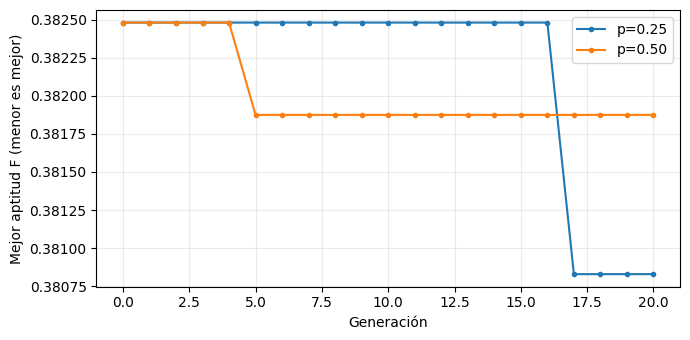

In [31]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generación', ylabel='Mejor aptitud F (menor es mejor)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## 11. Comprueba reproducción

Repite la configuración base con la misma semilla y comprueba igualdad de genes e historia. Reinicia el kernel y ejecuta de arriba abajo para descartar dependencias de ejecuciones previas. Esta repetición es una comprobación técnica, no una tercera configuración experimental.

In [32]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproducción y elitismo comprobados.')

Reproducción y elitismo comprobados.


## 12. Conserva evidencia en la misma libreta

- **Investigación (15%)**: formulación y supuestos (60/100); cálculo manual y contraste con el evaluador (40/100).
- **Desarrollo (15%)**: ciclo y operadores funcionales (70/100); una ejecución reproducible e interpretada (30/100).
- **Entrega final (30%)**: explicación de una generación (40/100); dos configuraciones y gráfica (35/100); interpretación física y límites (25/100).

En la entrega final reutiliza las secciones anteriores y añade la explicación de tu equipo. Identifica la base común y cualquier cambio propio. Las funciones adicionales no son necesarias para obtener 100. Conserva los archivos de entorno proporcionados junto a la libreta. La evaluación conjunta del código aporta 10% y el examen individual de artículos 30%. Consulta niveles y fechas en la [guía](guia_reto_planta_fisica.pdf).

## Procedencia y entorno

Usamos `assets/kit/datos/consumo_agua_2023_2026.csv` y `assets/kit/parametros_reto.csv` del repositorio técnico MA2015-Planta-Fisica, filtrados a marzo de 2025. La metadata conserva los cuatro registros y los hashes de las fuentes completas. El caso mensual y el código son autónomos.

Con Python 3.12–3.14 y los archivos proporcionados, prepara el entorno con `uv sync --locked` y abre Jupyter con `uv run jupyter lab`. NumPy realiza los cálculos y Matplotlib dibuja la gráfica. Los resultados representan este modelo didáctico, no una recomendación hidráulica o sanitaria validada.